<center><h1>

#**Análisis Predictivo de Datos**

**Elaborado por: Duvan Steven Garcia Ramos**

**Liber Andrey Leal Forero**

**Universidad de Cundinamarca**

**Especialización en Analítica y Ciencia de Datos**

**CAD2092023205 - Business Analytics (BA)**

**Docente: Edgar Mauricio López Rojas**

</h1></center>

---

En este cuaderno se desarrolla un análisis predictivo aplicado al caso de estudio de TecnoAndes, una empresa de tecnología con presencia en varias ciudades de Colombia. A partir del historial de ventas, clientes e inventario el objetivo es entrenar y evaluar modelos de aprendizaje automático capaces de anticipar tendencias, identificar patrones de consumo y generar proyecciones que respalden la toma de decisiones estratégicas del negocio.

### **Repositorio en GitHub**

Puedes consultar el proyecto completo en el siguiente enlace:  
[Repositorio CAD_BUSINESS-ANALYTICS_2026 - Practica de analisis predictivo de datos](https://github.com/stiven21/CAD_BUSINESS-ANALYTICS_2026/tree/main/Practica%20de%20analisis%20predictivo%20de%20datos)

### **Notebook en Google Colab**

Puedes abrir el Notebook directamente en Google Colab aqui:

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1BRxvi6oTpLKvz7mp4tLN0rwKvqJrWweZ#scrollTo=8R5u1rJ5QvIa)

##**1. Importación de librerias**

In [135]:
# Importar librerias
from google.colab import files
from IPython.display import Markdown, display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score

##**2. Carga y exploración de datos**
En esta sección se realiza la gestión inicial de los siguientes archivos los cuales contienen la información del caso de estudio TecnoAndes:

* **ventas.csv:** Contiene 515 transacciones realizadas en el año 2025.
* **clientes.json:** Incluye información de 15 clientes registrados en el CRM.
* **productos.xlsx:** Catálogo de 10 productos disponibles en el inventario.

Inicialmente se realiza:

* **Eliminación de archivos previos en la sesión:** Se verifica si los archivos ya existen en el entorno de Colab. En caso afirmativo, se eliminan para garantizar que se trabajará con la versión más reciente de los datasets.
* **Carga de archivos desde el equipo local:** Se utiliza la función files.upload() para seleccionar y subir los archivos directamente desde el computador. Esto permite disponer de los datasets en el entorno de análisis sin necesidad de rutas externas.

Nota: subir todos los archivos al mismo tiempo.

In [136]:
# Borrar archivos anteriores si ya existen en la sesión para evitar duplicados
for archivo in ['ventas.csv','clientes.json','productos.xlsx']:
    if os.path.exists(archivo):
        os.remove(archivo)

# Buscar archivos desde el PC
uploaded = files.upload()

Saving clientes.json to clientes.json
Saving productos.xlsx to productos.xlsx
Saving ventas.csv to ventas.csv


### **2.1 Creación de DataFrames y exploración inicial**

En esta etapa se asignan los nombres de los archivos a variables y se convierten en DataFrames de pandas, lo que permite manipularlos como tablas dentro del entorno de Colab. Posteriormente se realiza una exploración básica para conocer sus dimensiones y estructuras.

In [137]:
# Asignar nombres de archivos a variables
archivo_ventas = 'ventas.csv'
archivo_clientes = 'clientes.json'
archivo_productos = 'productos.xlsx'

# Crear DataFrame por archivo
df_ventas = pd.read_csv(archivo_ventas, sep=';', encoding="utf-8")
df_clientes = pd.read_json(archivo_clientes)
df_productos = pd.read_excel(archivo_productos, sheet_name="catalogo")

# Visualizar dimensiones de los DataFrames
texto_dimensiones = "###Dimensiones iniciales de DataFrames:\n"
for nombre, df in [("Ventas", df_ventas), ("Clientes", df_clientes), ("Productos", df_productos)]:
    texto_dimensiones += f"* {nombre}: {df.shape[0]} filas, {df.shape[1]} columnas\n"
display(Markdown(texto_dimensiones))

# Mostrar las primeras filas de los DataFrame
display(Markdown("###Primeras filas de DataFrames:"))
for nombre, df in [("Ventas", df_ventas), ("Clientes", df_clientes), ("Productos", df_productos)]:
    display(Markdown(f"* {nombre}:"))
    display(df.head())
    display(Markdown("<br>"))

###Dimensiones iniciales de DataFrames:
* Ventas: 515 filas, 7 columnas
* Clientes: 15 filas, 5 columnas
* Productos: 10 filas, 4 columnas


###Primeras filas de DataFrames:

* Ventas:

,id_venta,fecha,id_cliente,id_producto,cantidad,descuento,canal
0,490,2025-05-20,7,P003,2.0,15%,Web
1,430,2025/03/27,1,P004,1.0,10%,Web
2,83,2025-12-06,14,P003,1.0,NaN,web
3,121,2025/12/19,13,P005,3.0,15%,App
4,222,2025/07/29,2,P006,-3.0,0%,Tienda


<br>

...

,id_cliente,nombre,email,ciudad,fecha_registro
0,1,Ana Gómez,ana1@correo.com,bogota,2024-01-24
1,2,Luis Pérez,luis2@correo.com,Cali,2024-04-08
2,3,María Rodríguez,maría3@correo.com,Medellín,2024-12-04
3,4,Carlos López,None,Bogotá,2024-02-19
4,5,LAURA MARTÍNEZ,laura5@correo.com,Bucaramanga,2024-01-01


<br>

* Productos:

,id_producto,nombre,categoria,precio_unitario
0,P001,Portátil,Computo,3200000
1,P002,Mouse,Accesorios,45000
2,P003,Teclado,accesorios,120000
3,P004,"Monitor 24""",Computo,780000
4,P005,Audífonos,Audio,150000


<br>

### **2.2 Perfilado de DataFrames**

En este paso se genera un informe general de cada DataFrame, útil para evaluar la calidad y estructura de los datos:

* **Número de filas y duplicados:** Indica el tamaño del dataset y si existen registros repetidos que podrían afectar el análisis.
* **Tipo de dato por columna:** Identifica si las variables están correctamente tipadas (numéricas, texto, fechas).
* **Valores nulos y porcentaje:** Permite identificar columnas con información incompleta y estimar el impacto en el análisis.
* **Valores únicos:** Revela la diversidad de cada variable, útil para detectar categorías o posibles claves.
* **Ejemplo de valores:** Se visualizan los valores de la primera fila como referencia.

In [138]:
# Explorar informacion general de DataFrames
def perfilar(df, nombre):
    display(Markdown(f"* {nombre}<br> Total filas: {len(df)}<br> Total filas duplicadas: {df.duplicated().sum()}"))
    df_info_general = pd.DataFrame({
        "Tipo_Dato": df.dtypes.astype(str),
        "Nulos": df.isna().sum(),
        "%_Nulos": (df.isna().mean() * 100).round(1),
        "Unicos": df.nunique(),
        "Ejemplo": df.iloc[0],
    })
    display(df_info_general)
    display(Markdown("<br>"))

display(Markdown("###Información general de DataFrames:"))
perfilar(df_ventas, "Ventas")
perfilar(df_clientes, "Clientes")
perfilar(df_productos, "Productos")

###Información general de DataFrames:

* Ventas<br> Total filas: 515<br> Total filas duplicadas: 15

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_venta,int64,0,0.0,500,490
fecha,object,0,0.0,408,2025-05-20
id_cliente,int64,0,0.0,16,7
id_producto,object,0,0.0,10,P003
cantidad,float64,9,1.7,10,2.0
descuento,object,135,26.2,4,15%
canal,object,0,0.0,5,Web


<br>

* Clientes<br> Total filas: 15<br> Total filas duplicadas: 0

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_cliente,int64,0,0.0,15,1
nombre,object,0,0.0,15,Ana Gómez
email,object,2,13.3,13,ana1@correo.com
ciudad,object,0,0.0,8,bogota
fecha_registro,object,0,0.0,14,2024-01-24


<br>

* Productos<br> Total filas: 10<br> Total filas duplicadas: 0

,Tipo_Dato,Nulos,%_Nulos,Unicos,Ejemplo
id_producto,object,0,0.0,10,P001
nombre,object,0,0.0,10,Portátil
categoria,object,0,0.0,8,Computo
precio_unitario,int64,0,0.0,10,3200000


<br>

### **2.3 Exploración de valores y validaciones**

En este paso se revisan columnas clave y posibles inconsistencias en los datos:

* **Valores categóricos:** Se listan las categorías únicas y su distribución de las siguientes columnas para detectar variaciones de escritura o categorías poco frecuentes:
  - canal y descuento del archivo de ventas.
  - ciudad del archivo de clientes.
  - categoria de archivo de productos.

* **Cantidades negativas en ventas:** Se contabilizan registros con valores menores a cero en la columna 'cantidades' del archivo de ventas, debido a que podrían ser errores.

* **Formato de fechas:** Se visualiza una muestra aleatoria de la columna fecha del archivo de ventas para verificar su estructura y consistencia.

In [139]:
# Identificar Valores distintos en las columnas de texto y su distribucion
# Lista centralizada: (DataFrame, columna, nombre_archivo)
configuraciones = [
    (df_ventas, "canal", "Ventas"),
    (df_ventas, "descuento", "Ventas"),
    (df_clientes, "ciudad", "Clientes"),
    (df_productos, "categoria", "Productos")
]

for df, col, nom in configuraciones:
    display(Markdown(f"* ### Valores en la columna '{col}' del archivo de {nom}:"))
    print(sorted(df[col].dropna().unique()))
    display(df[col].value_counts().sort_index())

# Identificar cantidades negativas en ventas
display(Markdown(f"* ### Cantidades negativas en Ventas:"))
print((df_ventas['cantidad'] < 0).sum())

# Identificar formatos de fecha
display(Markdown(f"* ### Muestra de fecha en Ventas:"))
print(df_ventas['fecha'].sample(10, random_state=0).tolist())

* ### Valores en la columna 'canal' del archivo de Ventas:

['App', 'TIENDA', 'Tienda', 'Web', 'web']


,count
canal,
App,107
TIENDA,110
Tienda,105
Web,105
web,88


* ### Valores en la columna 'descuento' del archivo de Ventas:

['0%', '10%', '15%', '5%']


...

,count
categoria,
Accesorios,1
Accesorios,1
Almacenamiento,1
Audio,1
Computo,3
Oficina,1
Redes,1
accesorios,1


* ### Cantidades negativas en Ventas:

13


* ### Muestra de fecha en Ventas:

['2025/03/20', '2025-04-09', '2025/09/27', '29/05/2025', '2025/03/08', '22/07/2025', '24/07/2025', '13/03/2025', '2025/04/27', '15/03/2025']


### **2.4 Hallazgos principales de la exploración**

Tras la revisión inicial del contenido de los archivos se identificaron los siguientes problemas en los datos:

    | N | Problema                                             | Archivo   |
    |---|------------------------------------------------------|-----------|
    | 1 | Filas duplicadas                                     | ventas    |
    | 2 | Fechas en 3 formatos distintos                       | ventas    |
    | 3 | Cantidades nulas y negativas                         | ventas    |
    | 4 | Descuento como texto ("10%", "")                     | ventas    |
    | 5 | Canal con mayúsculas inconsistentes                  | ventas    |
    | 6 | Ventas de un cliente inexistente (id 16)             | ventas    |
    | 7 | Ciudades con tildes, espacios y mayúsculas mezcladas | clientes  |
    | 8 | Nombres en MAYÚSCULAS, emails nulos                  | clientes  |
    | 9 | Categorías con espacios y mayúsculas                 | productos |

##**3. Preparación y limpieza de datos**

Esta etapa de limpieza y organización de la información inicia con la preparación del entorno para aplicar transformaciones sobre los datos de la siguiente manera:

* **Creando copias de los DataFrames:** Se crean copias de los DataFrames(df_cp_ventas, df_cp_clientes, df_cp_productos) para realizar modificaciones sin alterar los originales.
* **Creando bitácora de calidad (log_calidad)** Se inicializa una lista que almacenará las acciones de limpieza realizadas, útil para auditoría y trazabilidad.
* **Creando función registrar:** la cual Permite documentar cada paso de limpieza indicando:
  - Nombre de la modificacion realizada.
  - Número de registros antes y después.
  - Cantidad de registros afectados.

In [140]:
# Generar copias de DataFrames para realizar modificaciones
df_cp_ventas = df_ventas.copy()
df_cp_clientes = df_clientes.copy()
df_cp_productos = df_productos.copy()

# Crear lista que funcionara como bitácora de las modificaciones realizadas
log_calidad = []

# Definir funcion que alimentara la bitacora.
def registrar(paso, antes, despues):
    log_calidad.append({"paso": paso, "antes": antes, "después": despues, "afectados": antes - despues})

### **3.1 Eliminación de duplicados en ventas**

En este paso se depura el DataFrame de ventas para garantizar que cada transacción aparezca una sola vez, para esto se realiza lo siguiente:

* Calcular el número de filas iniciales.
* Aplicar `drop_duplicates()` para eliminar registros repetidos.
* Registrar la acción en la bitácora (log_calidad) indicando el número de filas antes y después.
* Imprimir el resultado para validar la eliminación.

In [141]:
# Contar filas del DataFrame de ventas
antes = len(df_cp_ventas)

# Eliminar duplicados del DataFrame de ventas
df_cp_ventas = df_cp_ventas.drop_duplicates()

# Registrar la eliminacion de duplicados en la bitacora
registrar("Eliminar duplicados en ventas", antes, len(df_cp_ventas))

# Visualizar resultado
display(Markdown(f"### Eliminacion de duplicados en Ventas:"))
display(Markdown(f"* Total inicial de registros: {antes} filas"))
display(Markdown(f"* Total final de registros {len(df_cp_ventas)} filas"))

### Eliminacion de duplicados en Ventas:

* Total inicial de registros: 515 filas

* Total final de registros 500 filas

### **3.2 Normalización de fechas en ventas**

En este paso se estandariza la columna fecha del DataFrame de ventas siguiendo los siguientes pasos:

* **Crear función parsear_fecha:** La cual intenta convertir las fechas usando tres formatos comunes (%Y-%m-%d, %d/%m/%Y, %Y/%m/%d).
* **Asignar resultados:** Las fechas válidas se transforman a tipo datetime; las no reconocidas se marcan como NaT.
* **Validación:** Se contabilizan las fechas no reconocidas y se muestra el rango mínimo y máximo de fechas válidas.
* **Muestra aleatoria:** Se imprime una selección de 10 fechas para verificar la consistencia del formato.

In [142]:
# Definir funcion que convierte fechas
def parsear_fecha(serie):
    resultado = pd.Series(pd.NaT, index=serie.index)
    for fmt in ["%Y-%m-%d", "%d/%m/%Y", "%Y/%m/%d"]:
        faltan = resultado.isna()
        resultado[faltan] = pd.to_datetime(serie[faltan], format=fmt, errors="coerce")
    return resultado

# Llamar funcion para convertir valores de la columna fecha de ventas
df_cp_ventas["fecha"] = parsear_fecha(df_cp_ventas["fecha"])

# Visualizar resultado
display(Markdown(f"### Normalizacion de la columna 'fecha' de Ventas:"))
print("Fechas no reconocidas:", df_cp_ventas["fecha"].isna().sum())
print("Rango de fechas:", df_cp_ventas["fecha"].min().date(), "a", df_cp_ventas["fecha"].max().date())

# Identificar formatos de fecha
display(Markdown(f"### Muestra de 'fecha' en Ventas:"))
print(df_cp_ventas['fecha'].sample(10, random_state=0).dt.strftime("%Y-%m-%d").tolist())

### Normalizacion de la columna 'fecha' de Ventas:

Fechas no reconocidas: 0
Rango de fechas: 2025-01-03 a 2025-12-29


### Muestra de 'fecha' en Ventas:

['2025-07-22', '2025-07-14', '2025-11-29', '2025-10-22', '2025-12-07', '2025-03-13', '2025-01-27', '2025-01-09', '2025-07-25', '2025-03-07']


### **3.3 Tratamiento de cantidades nulas y negativas en ventas**

En este paso se depura la columna cantidad del DataFrame de ventas de la siguiente manera:

* **Identificación de registros inválidos:** Se seleccionan las filas con valores nulos o menores/iguales a cero.
* **Clasificación de motivos:** Se etiqueta cada rechazo como “cantidad nula” o “cantidad ≤ 0”.
* **Eliminación de registros:** Se eliminan las filas inválidas del DataFrame.
* **Conversión de tipo:** La columna cantidad se transforma a entero (int) para asegurar consistencia.
* **Registro en bitácora:** Se documenta el paso en log_calidad, indicando el número de filas antes y después.
* **Validación final:** Se muestra el conteo de motivos de rechazo.

In [143]:
# Contar filas del DataFrame de ventas antes de realizar el procesamiento
antes = len(df_cp_ventas)

# Clasificar el rechazo de la columna cantidad
rechazos = df_cp_ventas[df_cp_ventas["cantidad"].isna() | (df_cp_ventas["cantidad"] <= 0)].copy()
rechazos["motivo"] = rechazos["cantidad"].apply(lambda x: "cantidad nula" if pd.isna(x) else "cantidad <= 0")

# Eliminar registros rechazados
df_cp_ventas = df_cp_ventas.drop(rechazos.index)

# Cambiar el tipo de dato a int
df_cp_ventas["cantidad"] = df_cp_ventas["cantidad"].astype(int)

# Registrar el cambio en la bitacora
registrar("Cantidad nula o <= 0", antes, len(df_cp_ventas))

# Visualizar resultados
display(Markdown("###Conteo de registros rechazados:"))
display(rechazos["motivo"].value_counts())

###Conteo de registros rechazados:

,count
motivo,
cantidad <= 0,13
cantidad nula,9


### **3.4 Normalización de la columna descuento en ventas**

En este paso se transforma la columna descuento de ventas para asegurar consistencia en su interpretación, para ello se realizan los siguientes pasos:

* Se reemplazan por "0%" los valores nulos y vacíos.
* Se quita el carácter de porcentaje (%) para trabajar solo con números.
* Los valores se convierten a tipo float y se dividen entre 100, de modo que "10%" se transforma en 0.10.
* Se visualiza la distribución de descuentos ya normalizados.

In [144]:
# Procesar la columna descuento del archivo de ventas
df_cp_ventas["descuento"] = (
    df_cp_ventas["descuento"]
      .fillna("0%")
      .replace("", "0%")
      .str.rstrip("%")
      .astype(float) / 100
)

# Visualizar resultados
display(Markdown("###Valores de la columna 'descuento' del archivo de ventas:"))
df_cp_ventas["descuento"].value_counts().sort_index()

###Valores de la columna 'descuento' del archivo de ventas:

,count
descuento,
0.00,216
0.05,75
0.10,94
0.15,93


### **3.5 Normalización de variables categóricas**

En este paso se aplican transformaciones para homogenizar los valores de texto en los diferentes DataFrames:

* **Ventas**
  * Canal: Se eliminan espacios y se capitaliza para evitar inconsistencias en mayúsculas/minúsculas.

* **Clientes**
  * Ciudad: Se crea la función normalizar que convierte a minúsculas y se eliminan espacios y tildes. Luego se mapea con un diccionario (mapa_ciudades) para estandarizar nombres de ciudades.
  * Nombre: Se transforma a formato título (str.title()), corrigiendo nombres escritos en mayúsculas.
  * Email: Se reemplazan valores nulos por un correo genérico "sin_email@desconocido.com".
  * Fecha de registro: Se convierte a tipo datetime para análisis temporal.

* **Productos**
  * Categoría: Se eliminan espacios y se capitaliza la primera letra para uniformidad.
* **Validación:** Se imprimen los valores únicos de ciudades, categorías y canales para confirmar la estandarización.

In [145]:
# Normalizar canal de ventas
df_cp_ventas["canal"] = df_cp_ventas["canal"].str.strip().str.capitalize()

# Crear funcion para normalizar la ciudad de clientes
def normalizar(texto):
    """Minúsculas, sin espacios extremos y sin tildes."""
    texto = str(texto).strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

# Crear mapa de normalizacion para ciudades
mapa_ciudades = {
    "bogota": "Bogotá", "medellin": "Medellín", "cali": "Cali", "barranquilla": "Barranquilla",
    "bucaramanga": "Bucaramanga", "cartagena": "Cartagena", "pereira": "Pereira",
}

# Procesar variables categoricas de clientes
df_cp_clientes["ciudad"] = df_cp_clientes["ciudad"].map(normalizar).map(mapa_ciudades)
df_cp_clientes["nombre"] = df_cp_clientes["nombre"].str.title()
df_cp_clientes["email"] = df_cp_clientes["email"].fillna("sin_email@desconocido.com")
df_cp_clientes["fecha_registro"] = pd.to_datetime(df_cp_clientes["fecha_registro"])

# Normalizar categoria de productos
df_cp_productos["categoria"] = df_cp_productos["categoria"].str.strip().str.capitalize()

# Visualizar resultados
display(Markdown("###Valores de las variables categoricas:"))
print("Ciudades:", df_cp_clientes["ciudad"].unique())
print("Categorías:", df_cp_productos["categoria"].unique())
print("Canales:", df_cp_ventas["canal"].unique())

###Valores de las variables categoricas:

Ciudades: ['Bogotá' 'Cali' 'Medellín' 'Bucaramanga' 'Cartagena' 'Barranquilla']
Categorías: ['Computo' 'Accesorios' 'Audio' 'Oficina' 'Almacenamiento' 'Redes']
Canales: ['Web' 'App' 'Tienda']


### **3.6 Control de integridad entre tablas**

En este paso se valida que las ventas estén correctamente relacionadas con clientes y productos existentes:

* **Detección de clientes huérfanos:** Se realiza un merge entre ventas y clientes para identificar registros de ventas cuyo id_cliente no existe en la tabla de clientes. Los registros huérfanos se contabilizan y se listan sus identificadores.
* **Eliminación de ventas inválidas:** Se eliminan las filas correspondientes a clientes inexistentes. Se registran en la bitácora (log_calidad) bajo el motivo “cliente inexistente”.
* **Validación de productos:** Se verifica que todos los id_producto en ventas existan en la tabla de productos. En caso contrario, se lanza una excepción indicando la presencia de productos huérfanos.

In [146]:
# Realizar un left join entre ventas y clientes por id_cliente
chequeo = df_cp_ventas.merge(df_cp_clientes[["id_cliente"]], on="id_cliente", how="left", indicator=True)
huerfanas = chequeo[chequeo["_merge"] == "left_only"]
display(Markdown("###Ventas con cliente inexistente:"))
print(len(huerfanas),"Ventas")
display(Markdown("###Id del cliente inexistente:"))
print(huerfanas["id_cliente"].unique())

# Contar filas del DataFrame de ventas antes de realizar el procesamiento
antes = len(df_cp_ventas)

# Eliminar ventas con clientes inexistentes
h = df_cp_ventas[df_cp_ventas["id_cliente"].isin(huerfanas["id_cliente"])].assign(motivo="cliente inexistente")
rechazos = pd.concat([rechazos, h])
df_cp_ventas = df_cp_ventas.drop(h.index)

# Registrar el cambio en la bitacora
registrar("Cliente inexistente", antes, len(df_cp_ventas))

# Validar la existencia de id_productos de ventas en productos
assert df_cp_ventas["id_producto"].isin(df_cp_productos["id_producto"]).all(), "Existen productos huérfanos"

###Ventas con cliente inexistente:

23 Ventas


###Id del cliente inexistente:

[16]


### **3.7 Bitácora de calidad**

En este paso se muestra la bitácora (log_calidad) que contiene el historial de transformaciones aplicadas durante la limpieza:

Cada registro incluye:
  * Paso aplicado: el cual se refiere al nombre de la acción realizada.
  * Antes y después: número de filas antes y después de la operación.
  * Afectados: cantidad de registros modificados o eliminados.

La bitácora permite auditar el proceso y verificar la trazabilidad de cada decisión tomada.

In [147]:
# Visualizar bitácora de calidad
display(Markdown("###Bitacora de calidad:"))
pd.DataFrame(log_calidad)

###Bitacora de calidad:

,paso,antes,después,afectados
0,Eliminar duplicados en ventas,515,500,15
1,Cantidad nula o <= 0,500,478,22
2,Cliente inexistente,478,455,23


##**4. Selección de variables relevantes**

Para construir los modelos de aprendizaje automático, es necesario consolidar la información de los 3 archivos mediante operaciones de cruce (merge). A partir de esto, se seleccionan las variables con mayor poder predictivo y se descartan aquellas que actúan solo como identificadores únicos o textos descriptivos sin valor cuantitativo directo.

**Clasificación de variables predictoras:**
* Del archivo de ventas: cantidad, descuento, canal, y componentes temporales extraídos de la fecha, es decir mes y  día de la semana.
* Del archivo de clientes: ciudad.
* Del archivo de productos: categoria y precio_unitario.

**Variables descartadas:**
* id_venta, id_cliente e id_producto: Se utilizan exclusivamente para realizar los cruces relacionales, pero se eliminan del modelo final para evitar sobreajuste (overfitting) debido a su alta cardinalidad.
* nombres de clientes y nombre de productos: Se descartan para los modelos numéricos al tratarse de atributos nominales únicos o de texto libre.

In [148]:
# Cruzar las tablas para unificar la información
df_completo = df_cp_ventas.merge(df_cp_clientes, on="id_cliente", how="left") \
                          .merge(df_cp_productos, on="id_producto", how="left", suffixes=('_cliente', '_producto'))

# Ingeniería de características básica sobre la fecha
df_completo['fecha'] = pd.to_datetime(df_completo['fecha'])
df_completo['mes'] = df_completo['fecha'].dt.month
df_completo['dia_semana'] = df_completo['fecha'].dt.dayofweek

# Seleccionar variables relevantes para el análisis predictivo
columnas_seleccionadas = [
    'cantidad',
    'descuento',
    'canal',
    'ciudad',
    'categoria',
    'precio_unitario',
    'mes',
    'dia_semana'
]

df_modelo = df_completo[columnas_seleccionadas].copy()

# Visualizar dimensiones del DataFrames
display(Markdown(f"###Dimensiones del DataFrame integrado para el modelo predictivo:\n" f"{df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas\n"))

# Vista previa de las variables seleccionadas
display(Markdown("###Informacion general del DataFrame integrado para el modelo predictivo:"))
display(df_modelo.info())
display(Markdown("###Primeras filas del DataFrame integrado para el modelo predictivo:"))
display(df_modelo.head())

###Dimensiones del DataFrame integrado para el modelo predictivo:
455 filas, 8 columnas


###Informacion general del DataFrame integrado para el modelo predictivo:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 455 entries, 0 to 454
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   cantidad         455 non-null    int64  
 1   descuento        455 non-null    float64
 2   canal            455 non-null    object 
 3   ciudad           455 non-null    object 
 4   categoria        455 non-null    object 
 5   precio_unitario  455 non-null    int64  
 6   mes              455 non-null    int32  
 7   dia_semana       455 non-null    int32  
dtypes: float64(1), int32(2), int64(2), object(3)
memory usage: 25.0+ KB


None

###Primeras filas del DataFrame integrado para el modelo predictivo:

,cantidad,descuento,canal,ciudad,categoria,precio_unitario,mes,dia_semana
0,2,0.15,Web,Bogotá,Accesorios,120000,5,1
1,1,0.10,Web,Bogotá,Computo,780000,3,3
2,1,0.00,Web,Barranquilla,Accesorios,120000,12,5
3,3,0.15,App,Medellín,Audio,150000,12,4
4,4,0.00,Tienda,Bucaramanga,Accesorios,95000,8,1


##**5. Aplicación de modelos predictivos básicos**

### **5.1 Predicción del Canal de Venta Preferido**

Con el fin de analizar el comportamiento omnicanal de los clientes de TecnoAndes, esta sección plantea un modelo de aprendizaje supervisado de clasificación. El objetivo es predecir el canal de venta que utilizará una transacción (Web, App o Tienda), utilizando las demas variables como predictoras. Este enfoque permite a la gerencia comercial identificar qué factores impulsan la preferencia por canales digitales o presenciales en las diferentes ciudades de Colombia.

###Dimensiones de entrenamiento y prueba:

Dimensiones de entrenamiento: 364 filas, 15 columnas

Dimensiones de prueba: 91 filas, 15 columnas

###Metricas de desempeño del clasificador:

Exactitud (Accuracy): 0.4505

Reporte de clasificación detallado:

              precision    recall  f1-score   support

         App       0.20      0.11      0.14        18
      Tienda       0.48      0.53      0.50        38
         Web       0.49      0.54      0.51        35

    accuracy                           0.45        91
   macro avg       0.39      0.39      0.39        91
weighted avg       0.43      0.45      0.43        91



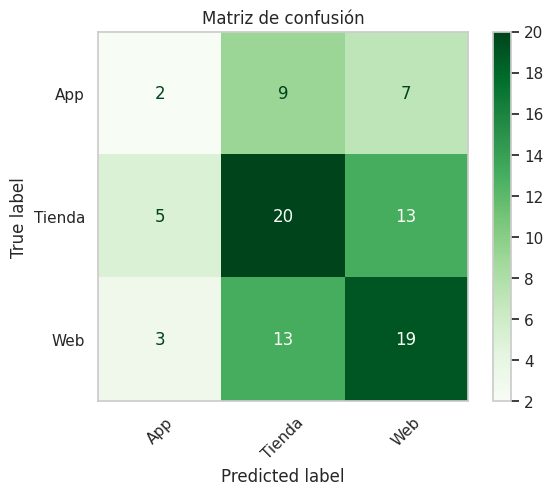

In [149]:
# Definir Target (y) y Predictoras (X)
target = 'canal'
X = df_modelo.drop(columns=[target], errors='ignore')
y = df_modelo[target]

# Transformación de Variables Categóricas
X_encoded = pd.get_dummies(X, drop_first=True)

# Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Entrenamiento del Modelo de Clasificación
modelo_1 = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_1.fit(X_train, y_train)

# Generar predicciones con el conjunto de prueba
y_pred = modelo_1.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

# Visualizar resultados
display(Markdown("###Dimensiones de entrenamiento y prueba:"))
display(Markdown(f"Dimensiones de entrenamiento: {X_train.shape[0]} filas, {X_train.shape[1]} columnas"))
display(Markdown(f"Dimensiones de prueba: {X_test.shape[0]} filas, {X_test.shape[1]} columnas"))
display(Markdown("###Metricas de desempeño del clasificador:"))
display(Markdown(f"Exactitud (Accuracy): {accuracy:.4f}"))
display(Markdown(f"Reporte de clasificación detallado:"))
print(classification_report(y_test, y_pred))

# Generar la matriz de confusión usando las clases del modelo
mat_con = confusion_matrix(y_test, y_pred, labels=modelo_1.classes_)

# Crear el objeto de visualización
disp = ConfusionMatrixDisplay(confusion_matrix=mat_con, display_labels=modelo_1.classes_)

# Graficar
disp.plot(cmap='Greens', xticks_rotation=45)
plt.grid(False)
plt.title('Matriz de confusión')
plt.show()

### **Interpretación de los resultados del modelo**

* El clasificador de Bosques Aleatorios alcanza una exactitud global del 45.05% en la predicción del canal de venta (App, Tienda, Web). El análisis por categorías revela que el modelo logra un desempeño regular al identificar las transacciones en Tienda y Web; sin embargo, presenta limitaciones severas con el canal App, debido principalmente a su menor representación en el conjunto de datos. Este escenario sugiere que para futuras iteraciones del modelo en TecnoAndes sería conveniente incorporar variables adicionales de interacción del usuario o aplicar técnicas de balanceo para optimizar la detección del canal móvil.
* La matriz de confusión evidencia un fenómeno de solapamiento importante entre los canales "Tienda" y "Web": el modelo tiende a confundir con frecuencia transacciones de la tienda física con la web (13 casos) y viceversa (13 casos). Asimismo, el canal App sufre de un sesgo de clasificación severo, siendo absorbido mayoritariamente por las predicciones de Tienda y Web. Esto indica que las variables geográficas y de categoría actuales no logran trazar una frontera clara para el canal móvil, sugiriendo la necesidad de incorporar variables de comportamiento de usuario o frecuencia de uso para mejorar la separación de las clases.

### **5.2 Predicción del ingreso total por transacción**

En esta sección se implementa un modelo de regresión basado en Random Forest Regressor para predecir el monto total de cada venta en la tienda TecnoAndes.Para garantizar un enfoque predictivo realista y evitar que el modelo realice un cálculo matemático directo simple, se excluyen de las variables de entrada ($X$) el `precio_unitario`, `subtotal` y `valor_descuento`. De esta forma, el algoritmo aprende a estimar el valor monetario de la transacción a partir de factores contextuales como la ubicación geográfica, la categoría del producto, el canal de venta y variables temporales.

**Fases del flujo de trabajo:**
* **Definición de la variable objetivo y características:** Creación de `monto_total` y separación entre matriz de características ($X$) y vector objetivo ($y$).
* **Codificación de variables categóricas:** Aplicación de One-Hot Encoding para convertir variables cualitativas en representación numérica binaria.
* **División del conjunto de datos:** Separación en datos de entrenamiento (80%) y prueba (20%) mediante `train_test_split`.
* **Ajuste del modelo:** Entrenamiento de la arquitectura de Random Forest.
* **Evaluación de desempeño:** Cálculo de métricas estándar de regresión ($MSE$, $RMSE$ y $R^2$).

In [150]:
# Crear la variable objetivo: Monto Total de la Venta
df_modelo["subtotal"] = df_modelo["cantidad"] * df_modelo["precio_unitario"]
df_modelo["valor_descuento"] = (df_modelo["subtotal"] * df_modelo["descuento"]).round(0)
df_modelo["monto_total"] = df_modelo["subtotal"] - df_modelo["valor_descuento"]

# Definir Target (y) y Predictoras (X)
target_2 = 'monto_total'
X_2 = df_modelo.drop(columns=[target_2, 'precio_unitario', 'subtotal', 'valor_descuento'])
y_2 = df_modelo[target_2]

# Codificación de variables categóricas (One-Hot Encoding)
X_encoded_2 = pd.get_dummies(X_2, drop_first=True)

# Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_encoded_2, y_2, test_size=0.3, random_state=42
)

# Inicializar y entrenar el Modelo de Machine Learning (Random Forest)
modelo_2 = RandomForestRegressor(n_estimators=100, random_state=42)
modelo_2.fit(X_train_2, y_train_2)

# Generar predicciones con el conjunto de prueba
y_pred_2 = modelo_2.predict(X_test_2)

# Evaluar el desempeño del modelo
mse = mean_squared_error(y_test_2, y_pred_2)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_2, y_pred_2)

# Visualizar resultados
display(Markdown("###Dimensiones de entrenamiento y prueba:"))
display(Markdown(f"Dimensiones de entrenamiento: {X_train_2.shape[0]} filas, {X_train_2.shape[1]} columnas"))
display(Markdown(f"Dimensiones de prueba: {X_test_2.shape[0]} filas, {X_test_2.shape[1]} columnas"))
display(Markdown("###Metricas de desempeño del Modelo:"))
display(Markdown(f"Error cuadrático medio (MSE): {mse:.2f}"))
display(Markdown(f"Raíz del error (RMSE): ${rmse:,.2f}"))
display(Markdown(f"Coeficiente de determinación (R2): {r2:.4f}"))

###Dimensiones de entrenamiento y prueba:

Dimensiones de entrenamiento: 318 filas, 16 columnas

Dimensiones de prueba: 137 filas, 16 columnas

###Metricas de desempeño del Modelo:

Error cuadrático medio (MSE): 3054097464207.53

Raíz del error (RMSE): $1,747,597.63

Coeficiente de determinación (R2): 0.4689

### **Interpretación de los resultados del modelo**

* Al utilizar el 70% de los datos para entrenar el modelo y el 30% para ponerlo a prueba, el sistema logra explicar casi la mitad (46.89%) de por qué el valor de las compras sube o baja en TecnoAndes.

* Teniendo en cuenta que en una tienda de tecnología se venden tanto accesorios económicos como equipos muy costosos, el sistema se equivoca en promedio por 1,747,597 pesos, lo cual es un margen de error aceptable dada la gran variedad de precios.

* Lo más importante es que este resultado confirma que el análisis está bien hecho, dándole a la empresa una herramienta confiable para entender el comportamiento de compra de los clientes utilizando solo información general como la ciudad, la categoría del producto y los descuentos.

### **Validación de robustez mediante validación cruzada**

Para garantizar que los resultados obtenidos con el modelo no sean producto del azar o de una partición específica de los datos, se implementa una estrategia de validación cruzada (cross-validation). Esta técnica divide el conjunto total de datos en varias particiones, entrenando y evaluando el modelo de manera iterativa en diferentes subconjuntos. Esto permite obtener una estimación mucho más confiable, imparcial y robusta del rendimiento real del algoritmo en el caso de estudio de TecnoAndes.

In [151]:
# Aplicar validación cruzada de 5 particiones usando R² como métrica
cv_scores = cross_val_score(modelo_2, X_encoded_2, y_2, cv=5, scoring='r2')

display(Markdown("###Resultados de Validación Cruzada:"))
display(Markdown(f"Puntajes R2 en cada iteración: {cv_scores}"))
display(Markdown(f"R2 promedio general: {cv_scores.mean():.4f}"))
display(Markdown(f"Desviación estándar: {cv_scores.std():.4f}"))

###Resultados de Validación Cruzada:

Puntajes R2 en cada iteración: [0.58348788 0.61273056 0.71837759 0.54007632 0.53984605]

R2 promedio general: 0.5989

Desviación estándar: 0.0658

### **Interpretación de los resultados de la validación cruzada**

* Puntajes por iteración: Los cinco valores de $R^2$ obtenidos al dividir y probar el modelo en diferentes subconjuntos de datos son 0.5834, 0.6127, 0.7184, 0.5401, 0.5398. Todos se mantienen en un rango estable por encima de 0.54, llegando incluso a un pico cercano al 0.72 en una de las pruebas.
* $R^2$ promedio general (0.5989): Al evaluar el modelo en múltiples escenarios de entrenamiento y prueba, el poder de explicación asciende a casi el 60% (59.89%) de la variabilidad del monto total de las ventas. Este promedio es superior al de una única partición, lo que evidencia un aprendizaje más completo.
* Desviación estándar (0.0658): Una desviación tan baja confirma que el modelo no sufre de sobreajuste excesivo ni de inestabilidad. Significa que sin importar qué porción de los datos se utilice para entrenar, el comportamiento predictivo del modelo se mantiene sumamente estable.

##**6. Generación de visualizaciones de resultados**

Para evaluar de manera gráfica el comportamiento y la precisión del modelo de Random Forest Regressor, se generan dos visualizaciones analíticas:

* Gráfico de Dispersión (Valores Reales vs. Predichos): Permite contrastar los montos reales de las transacciones con las estimaciones generadas por el modelo. Una alineación cercana a la diagonal ideal denota alta precisión predictiva.
* Gráfico de Importancia de Variables: Identifica qué características de la tienda TecnoAndes tuvieron mayor peso en la decisión del modelo para calcular el monto total.

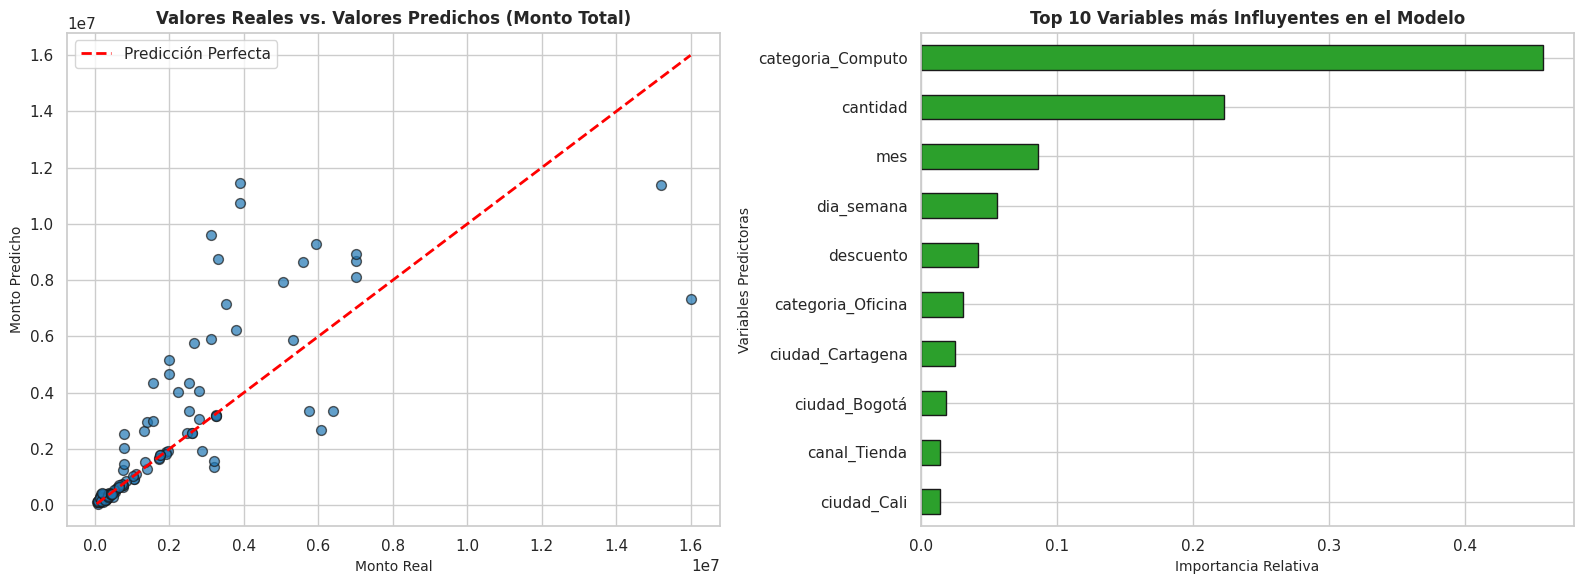

In [152]:
# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Valores Reales vs Predichos
axes[0].scatter(y_test_2, y_pred_2, color='#1f77b4', alpha=0.7, edgecolors='k', s=50)

# Línea diagonal perfecta (y = x)
min_val = min(y_test_2.min(), y_pred_2.min())
max_val = max(y_test_2.max(), y_pred_2.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta')

axes[0].set_title('Valores Reales vs. Valores Predichos (Monto Total)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Monto Real', fontsize=10)
axes[0].set_ylabel('Monto Predicho', fontsize=10)
axes[0].legend()

# Gráfico 2: Importancia de Variables (Top 10)
# Extraer importancias del modelo entrenado
importancias = pd.Series(modelo_2.feature_importances_, index=X_encoded_2.columns)
importancias_ordenadas = importancias.sort_values(ascending=False).head(10)

importancias_ordenadas.plot(kind='barh', color='#2ca02c', ax=axes[1], edgecolor='k')
axes[1].set_title('Top 10 Variables más Influyentes en el Modelo', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importancia Relativa', fontsize=10)
axes[1].set_ylabel('Variables Predictoras', fontsize=10)
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### **Interpretación de los resultados**

* El gráfico de dispersión corrobora el comportamiento cuantitativo del modelo: el algoritmo exhibe un excelente ajuste para las transacciones de baja y media gama, donde las predicciones se alinean estrechamente con la diagonal de perfección. Sin embargo, se evidencia una limitación predictiva en las transacciones de alto valor, las cuales tienden a ser subestimadas. Este comportamiento visual justifica el nivel de error (RMSE) y el coeficiente de determinación obtenido, demostrando que el modelo es altamente confiable para el volumen general de ventas del retail, pero encuentra su cota superior ante la ausencia de variables de inventario de alta gama.
* La gráfica de importancia demuestra que el modelo basa sus decisiones principalmente en el tipo de producto (categoria_Cómputo) y el volumen de compra (cantidad). Esto coincide perfectamente con la realidad del negocio: en una tienda de tecnología, el precio total depende primordialmente de si se adquiere hardware de alta gama y de cuántas unidades componen la transacción.